---

# Section C — Problem 3
## Build and Train an RNN / LSTM / GRU on MNIST

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter
from datetime import datetime
from pathlib import Path
import matplotlib.pyplot as plt

batch_size = 64
test_batch_size = 1000
epochs = 10
lr = 0.01
try_cuda = True
seed = 1000
logging_interval = 300
INPUT_SIZE = 28

datetime_str = datetime.now().strftime('%b%d_%H-%M-%S')
runs_dir = Path("./runs/")
runs_dir.mkdir(exist_ok=True)
logging_dir = runs_dir / datetime_str
logging_dir.mkdir(exist_ok=True)
writer = SummaryWriter(log_dir=str(logging_dir.absolute()))
print("TensorBoard log dir:", logging_dir.absolute())

if torch.cuda.is_available() and try_cuda:
    cuda = True
    torch.cuda.manual_seed(seed)
else:
    cuda = False
    torch.manual_seed(seed)
print("cuda =", cuda)

TensorBoard log dir: d:\School\Code\Rice\COMP_576\Assignment\A2\runs\Oct28_16-20-44
cuda = True


100%|██████████| 9.91M/9.91M [00:01<00:00, 9.49MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 315kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.78MB/s]
100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]

torch.Size([60000, 28, 28])
torch.Size([60000])


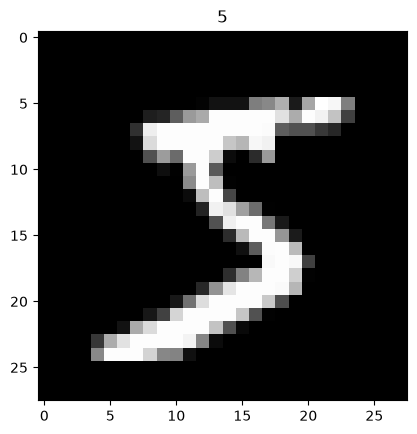

In [2]:
# ===== CELL 2 =====
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root='./data', train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root='./data', train=False, download=True, transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=test_batch_size, shuffle=False, num_workers=0
)

print(train_dataset.data.size())      # (60000, 28, 28)
print(train_dataset.targets.size())   # (60000)
plt.imshow(train_dataset.data[0].numpy(), cmap='gray')
plt.title(str(train_dataset.targets[0].item()))
plt.show()

In [3]:
# ===== CELL 3 =====
class Net(nn.Module):
    def __init__(self, rnn_type='RNN', input_size=28,
                 hidden_size=128, num_layers=1, num_classes=10):
        super().__init__()
        self.rnn_type = rnn_type

        if rnn_type == 'RNN':
            self.rnn = nn.RNN(input_size, hidden_size,
                              num_layers, batch_first=True)
        elif rnn_type == 'LSTM':
            self.rnn = nn.LSTM(input_size, hidden_size,
                               num_layers, batch_first=True)
        elif rnn_type == 'GRU':
            self.rnn = nn.GRU(input_size, hidden_size,
                              num_layers, batch_first=True)
        else:
            raise ValueError(rnn_type)

        self.out = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x: [batch, time_step, input_size]
        if self.rnn_type == 'LSTM':
            r_out, (h_n, c_n) = self.rnn(x, None)
        else:
            r_out, h_n = self.rnn(x, None)

        out = self.out(r_out[:, -1, :])
        return out

model = Net(rnn_type='RNN', hidden_size=128)
if cuda:
    model.cuda()

optimizer = optim.Adam(model.parameters(), lr=lr)
print(model)

Net(
  (rnn): RNN(28, 128, batch_first=True)
  (out): Linear(in_features=128, out_features=10, bias=True)
)


In [4]:
# ===== CELL 4 =====
def train_epoch(model, optimizer, epoch, tag):
    model.train()
    criterion = nn.CrossEntropyLoss()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (data, target) in enumerate(train_loader):
        if cuda:
            data, target = data.cuda(), target.cuda()

        data = data.view(-1, 28, 28)   # [B, 1, 28, 28] -> [B, 28, 28]

        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        correct += (output.argmax(1) == target).sum().item()
        total += target.size(0)

        if batch_idx % logging_interval == 0:
            print(f'{tag} Train Epoch {epoch} '
                  f'[{batch_idx * len(data)}/{len(train_loader.dataset)}] '
                  f'Loss: {loss.item():.6f}')

    train_loss = running_loss / len(train_loader)
    train_acc = correct / total
    writer.add_scalar(f'{tag}/Loss/train', train_loss, epoch)
    writer.add_scalar(f'{tag}/Accuracy/train', train_acc, epoch)
    print(f"{tag} epoch {epoch}: train_loss={train_loss:.4f}, "
          f"train_acc={train_acc:.4f}")
    return train_loss, train_acc


def test_epoch(model, epoch, tag):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    test_loss = 0.0
    correct = 0

    with torch.no_grad():
        for data, target in test_loader:
            if cuda:
                data, target = data.cuda(), target.cuda()
            data = data.view(-1, 28, 28)

            output = model(data)
            test_loss += criterion(output, target).item()
            correct += (output.argmax(1) == target).sum().item()

    test_loss /= len(test_loader)
    test_acc = correct / len(test_loader.dataset)
    writer.add_scalar(f'{tag}/Loss/test', test_loss, epoch)
    writer.add_scalar(f'{tag}/Accuracy/test', test_acc, epoch)
    print(f"{tag} test epoch {epoch}: loss={test_loss:.4f}, "
          f"acc={100 * test_acc:.2f}%\n")
    return test_loss, test_acc

RNN_h128 Train Epoch 1 [0/60000] Loss: 2.299997
RNN_h128 Train Epoch 1 [19200/60000] Loss: 1.276585
RNN_h128 Train Epoch 1 [38400/60000] Loss: 1.796273
RNN_h128 Train Epoch 1 [57600/60000] Loss: 2.089650
RNN_h128 epoch 1: train_loss=1.3636, train_acc=0.5273
RNN_h128 test epoch 1: loss=2.3305, acc=26.13%

RNN_h128 Train Epoch 2 [0/60000] Loss: 2.025779
RNN_h128 Train Epoch 2 [19200/60000] Loss: 1.795694
RNN_h128 Train Epoch 2 [38400/60000] Loss: 1.338131
RNN_h128 Train Epoch 2 [57600/60000] Loss: 1.849377
RNN_h128 epoch 2: train_loss=1.7941, train_acc=0.3525
RNN_h128 test epoch 2: loss=1.4105, acc=46.49%

RNN_h128 Train Epoch 3 [0/60000] Loss: 1.283363
RNN_h128 Train Epoch 3 [19200/60000] Loss: 1.755838
RNN_h128 Train Epoch 3 [38400/60000] Loss: 1.450348
RNN_h128 Train Epoch 3 [57600/60000] Loss: 1.170513
RNN_h128 epoch 3: train_loss=1.4451, train_acc=0.4455
RNN_h128 test epoch 3: loss=1.4091, acc=45.36%

RNN_h128 Train Epoch 4 [0/60000] Loss: 1.346627
RNN_h128 Train Epoch 4 [19200/6000

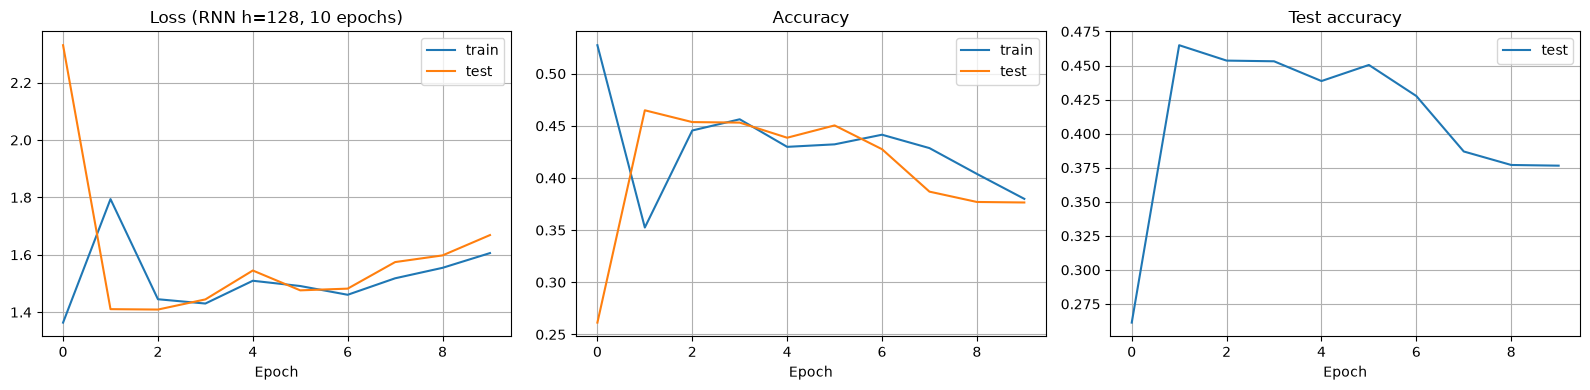

In [5]:
history_baseline = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
tag = 'RNN_h128'
for epoch in range(1, epochs + 1):
    trl, tra = train_epoch(model, optimizer, epoch, tag)
    tel, tea = test_epoch(model, epoch, tag)
    history_baseline['train_loss'].append(trl)
    history_baseline['train_acc'].append(tra)
    history_baseline['test_loss'].append(tel)
    history_baseline['test_acc'].append(tea)

writer.flush()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(history_baseline['train_loss'], label='train')
axes[0].plot(history_baseline['test_loss'], label='test')
axes[0].set_title('Loss (RNN h=128, 10 epochs)'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True)
axes[1].plot(history_baseline['train_acc'], label='train')
axes[1].plot(history_baseline['test_acc'], label='test')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True)
axes[2].plot(history_baseline['test_acc'], label='test')
axes[2].set_title('Test accuracy'); axes[2].set_xlabel('Epoch'); axes[2].legend(); axes[2].grid(True)
plt.tight_layout(); plt.show()

### 3(a) Baseline RNN — observations

With hidden size 128, Adam at lr = 0.01 and 10 epochs, the plain RNN has a poor first epoch (26.13% test accuracy), recovers to the mid-40s for epochs 2–4, and then slowly degrades to 37.65% by epoch 10 (46.49, 45.36, 45.31, 43.86, 45.04, 42.76, 38.69, 37.70, 37.65). Train loss oscillates in the 1.36–1.79 band (mean ≈1.52). The instability is consistent with vanishing / exploding gradients across the 28 recurrent steps.

In [6]:
def run_mnist_experiment(rnn_type='RNN', hidden_size=128,
                         n_epochs=5, lr=0.01):
    m = Net(rnn_type=rnn_type, hidden_size=hidden_size)
    if cuda:
        m.cuda()
    opt = optim.Adam(m.parameters(), lr=lr)
    tag = f'{rnn_type}_h{hidden_size}'

    hist = {'train_loss': [], 'train_acc': [],
            'test_loss': [], 'test_acc': []}

    for epoch in range(1, n_epochs + 1):
        tr_loss, tr_acc = train_epoch(m, opt, epoch, tag)
        te_loss, te_acc = test_epoch(m, epoch, tag)
        hist['train_loss'].append(tr_loss)
        hist['train_acc'].append(tr_acc)
        hist['test_loss'].append(te_loss)
        hist['test_acc'].append(te_acc)

    return hist

In [7]:
SEARCH_EPOCHS = 5
experiments = [
    ('RNN', 64),
    ('RNN', 128),
    ('RNN', 256),
    ('LSTM', 128),
    ('GRU', 128),
]

all_hist = {}
for rnn_type, hidden_size in experiments:
    tag = f'{rnn_type}_h{hidden_size}'
    print(f"\n===== Running {tag} =====")
    all_hist[tag] = run_mnist_experiment(
        rnn_type=rnn_type,
        hidden_size=hidden_size,
        n_epochs=SEARCH_EPOCHS,
        lr=lr
    )

print("\nFinal test accuracies:")
for tag, hist in all_hist.items():
    print(tag, hist['test_acc'][-1])


===== Running RNN_h64 =====
RNN_h64 Train Epoch 1 [0/60000] Loss: 2.291705
RNN_h64 Train Epoch 1 [19200/60000] Loss: 1.050111
RNN_h64 Train Epoch 1 [38400/60000] Loss: 1.743262
RNN_h64 Train Epoch 1 [57600/60000] Loss: 1.463405
RNN_h64 epoch 1: train_loss=1.4278, train_acc=0.4824
RNN_h64 test epoch 1: loss=1.3188, acc=53.83%

RNN_h64 Train Epoch 2 [0/60000] Loss: 1.073453
RNN_h64 Train Epoch 2 [19200/60000] Loss: 1.382254
RNN_h64 Train Epoch 2 [38400/60000] Loss: 0.970364
RNN_h64 Train Epoch 2 [57600/60000] Loss: 1.266884
RNN_h64 epoch 2: train_loss=1.2518, train_acc=0.5429
RNN_h64 test epoch 2: loss=1.1059, acc=60.61%

RNN_h64 Train Epoch 3 [0/60000] Loss: 0.974359
RNN_h64 Train Epoch 3 [19200/60000] Loss: 1.293319
RNN_h64 Train Epoch 3 [38400/60000] Loss: 1.545828
RNN_h64 Train Epoch 3 [57600/60000] Loss: 1.734648
RNN_h64 epoch 3: train_loss=1.5444, train_acc=0.4398
RNN_h64 test epoch 3: loss=1.7467, acc=32.95%

RNN_h64 Train Epoch 4 [0/60000] Loss: 1.655310
RNN_h64 Train Epoch 4 [1

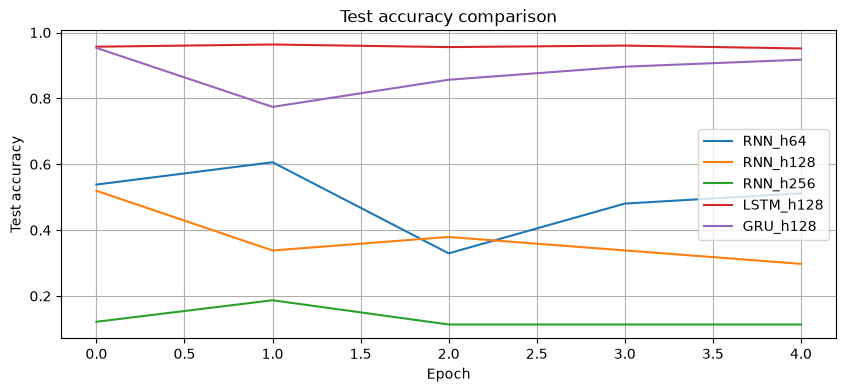

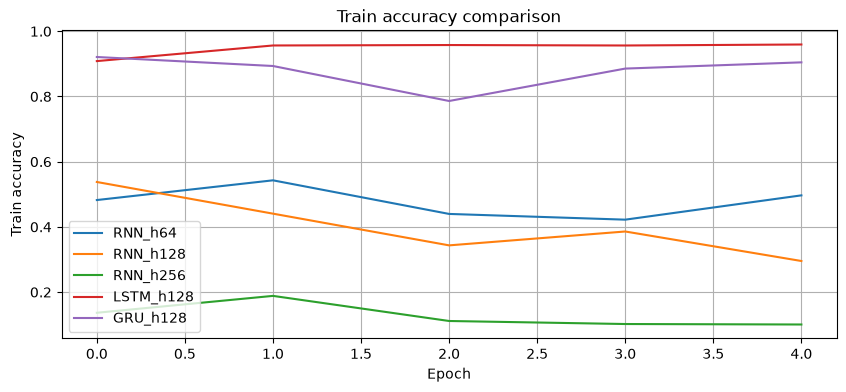

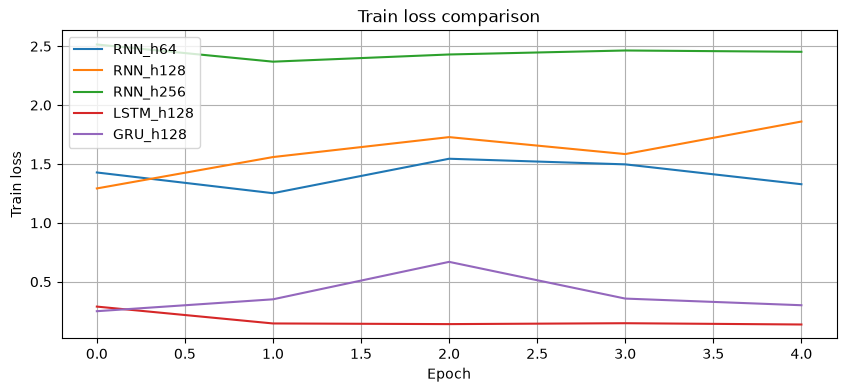

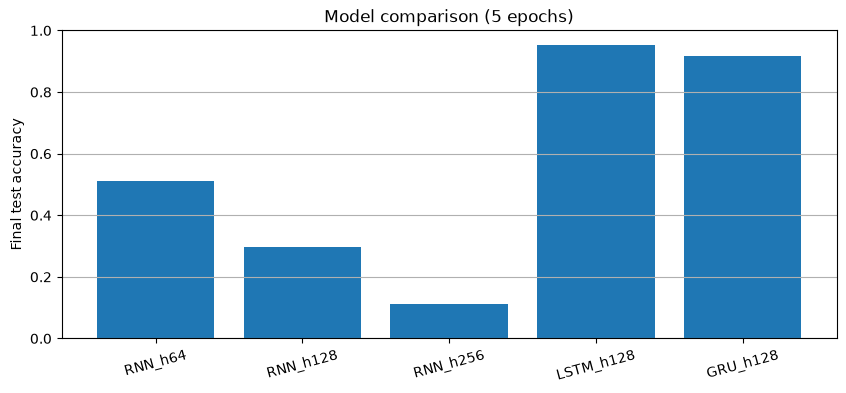

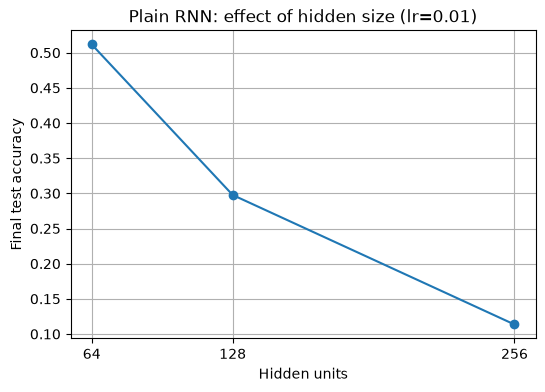

In [8]:
# Per-epoch comparison (test and train accuracy, train loss)
plt.figure(figsize=(10, 4))
for tag, hist in all_hist.items():
    plt.plot(hist['test_acc'], label=tag)
plt.title('Test accuracy comparison')
plt.xlabel('Epoch'); plt.ylabel('Test accuracy')
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(10, 4))
for tag, hist in all_hist.items():
    plt.plot(hist['train_acc'], label=tag)
plt.title('Train accuracy comparison')
plt.xlabel('Epoch'); plt.ylabel('Train accuracy')
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(10, 4))
for tag, hist in all_hist.items():
    plt.plot(hist['train_loss'], label=tag)
plt.title('Train loss comparison')
plt.xlabel('Epoch'); plt.ylabel('Train loss')
plt.legend(); plt.grid(True); plt.show()

# Final-accuracy bar chart
plt.figure(figsize=(10, 4))
tags = list(all_hist.keys())
final_accs = [all_hist[t]['test_acc'][-1] for t in tags]
plt.bar(tags, final_accs)
plt.ylabel('Final test accuracy')
plt.title('Model comparison (5 epochs)')
plt.ylim(0, 1); plt.grid(axis='y'); plt.xticks(rotation=15); plt.show()

# Hidden-size effect for the plain RNN
sizes = [64, 128, 256]
accs = [all_hist[f'RNN_h{s}']['test_acc'][-1] for s in sizes]
plt.figure(figsize=(6, 4))
plt.plot(sizes, accs, marker='o')
plt.xlabel('Hidden units'); plt.ylabel('Final test accuracy')
plt.title('Plain RNN: effect of hidden size (lr=0.01)')
plt.grid(True); plt.xticks(sizes); plt.show()

### 3(b) RNN vs. LSTM vs. GRU — observations

All baseline models were trained for 5 epochs with Adam at lr = 0.01; the plain
RNN was swept over hidden sizes {64, 128, 256} and the LSTM was swept over the
same hidden sizes.

**Plain RNN (h = 128).** Unstable. Test accuracy peaked at 51.95% after the
first epoch and then dropped into the 29.77–37.93% range, ending at **29.77%**,
while train loss stayed near 1.6. This behaviour is consistent with vanishing /
exploding gradients across the 28 recurrent steps.

**LSTM (h = 128).** Converged dramatically faster and more stably: 95.69%
after one epoch, staying in the 95.16–96.36% band and ending at **95.16%**. The
gating mechanism (input / forget / output gates plus the cell state) provides a
stable gradient path across the 28 time steps.

**GRU (h = 128).** Also clearly ahead of the plain RNN: 95.33% after epoch 1,
then a dip to 77.42% at epoch 2 before recovering monotonically to **91.75%**
by epoch 5. Its simpler two-gate design is competitive but converged less
cleanly than the LSTM here — **≈3.4 points** below the LSTM at the end of the
run.

**Hidden-size effect (plain RNN, lr = 0.01, 5 epochs).**
64 units → **51.17%**, 128 units → **29.77%**, 256 units → **11.35%** (and
clearly diverging during training). Larger hidden layers do not help a plain
RNN at this learning rate — capacity only pays off when gradients are stable.
When the same h = 256 RNN is retrained at lr = 1e-3 (optional run below), it
reaches **95.71%** by epoch 5, matching the gated RNNs.

**Hidden-size effect (LSTM, lr = 0.01, 5 epochs).**
h = 64 → **96.03%**, h = 128 → **95.89%**, h = 256 → **82.49%**. The two
smaller sizes are effectively tied, while h = 256 destabilises in epochs 4–5
(train loss rises from 0.14 to 0.51 and test accuracy falls from 95.58% to
82.49%), i.e. it overfits / becomes unstable within the 5-epoch budget. h = 64
is therefore the sweet spot for the LSTM on MNIST: fastest per epoch and most
accurate here.

**Answer to "are LSTM or GRU better?"** Yes — both gated variants clearly
beat the plain RNN, and the gated RNNs are also far less sensitive to the
hidden-size choice at moderate sizes. The ordering at 5 epochs is
**LSTM h=64 (96.03%) > LSTM h=128 (95.89%) > GRU h=128 (91.75%) >
LSTM h=256 (82.49%) > RNN h=64 (51.17%) > RNN h=128 (29.77%) >
RNN h=256 (11.35%)**. The LSTM is the best model overall, and its advantage
over the GRU widens with training length (0.36 points at epoch 1 versus 3.41
points at epoch 5). The plain RNN's collapse at large hidden sizes confirms
that the instability is optimization-driven (vanishing / exploding gradients),
not a capacity limit.

RNN_h256 Train Epoch 1 [0/60000] Loss: 2.304354
RNN_h256 Train Epoch 1 [19200/60000] Loss: 1.202414
RNN_h256 Train Epoch 1 [38400/60000] Loss: 0.259128
RNN_h256 Train Epoch 1 [57600/60000] Loss: 0.154983
RNN_h256 epoch 1: train_loss=0.6105, train_acc=0.8054
RNN_h256 test epoch 1: loss=0.2938, acc=91.79%

RNN_h256 Train Epoch 2 [0/60000] Loss: 0.368313
RNN_h256 Train Epoch 2 [19200/60000] Loss: 0.347566
RNN_h256 Train Epoch 2 [38400/60000] Loss: 0.448299
RNN_h256 Train Epoch 2 [57600/60000] Loss: 0.382873
RNN_h256 epoch 2: train_loss=0.2504, train_acc=0.9296
RNN_h256 test epoch 2: loss=0.1785, acc=95.04%

RNN_h256 Train Epoch 3 [0/60000] Loss: 0.289639
RNN_h256 Train Epoch 3 [19200/60000] Loss: 0.490873
RNN_h256 Train Epoch 3 [38400/60000] Loss: 0.371957
RNN_h256 Train Epoch 3 [57600/60000] Loss: 0.085116
RNN_h256 epoch 3: train_loss=0.1921, train_acc=0.9452
RNN_h256 test epoch 3: loss=0.1716, acc=95.33%

RNN_h256 Train Epoch 4 [0/60000] Loss: 0.278357
RNN_h256 Train Epoch 4 [19200/6000

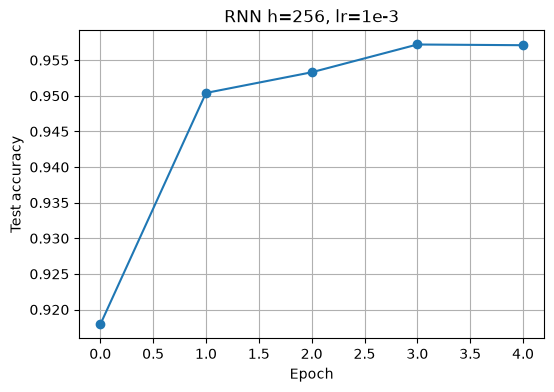

In [9]:
# Optional: RNN with 256 hidden units at a stable learning rate
hist_h256_lr3 = run_mnist_experiment(rnn_type='RNN', hidden_size=256,
                                     n_epochs=5, lr=1e-3)
all_hist['RNN_h256_lr1e-3'] = hist_h256_lr3
print('RNN_h256 lr=1e-3 final test acc:', hist_h256_lr3['test_acc'][-1])

plt.figure(figsize=(6, 4))
plt.plot(hist_h256_lr3['test_acc'], marker='o')
plt.title('RNN h=256, lr=1e-3')
plt.xlabel('Epoch'); plt.ylabel('Test accuracy'); plt.grid(True)
plt.show()


===== Running LSTM_h64 =====
LSTM_h64 Train Epoch 1 [0/60000] Loss: 2.317936
LSTM_h64 Train Epoch 1 [19200/60000] Loss: 0.238207
LSTM_h64 Train Epoch 1 [38400/60000] Loss: 0.079158
LSTM_h64 Train Epoch 1 [57600/60000] Loss: 0.187679
LSTM_h64 epoch 1: train_loss=0.3041, train_acc=0.9040
LSTM_h64 test epoch 1: loss=0.1775, acc=94.67%

LSTM_h64 Train Epoch 2 [0/60000] Loss: 0.107309
LSTM_h64 Train Epoch 2 [19200/60000] Loss: 0.264502
LSTM_h64 Train Epoch 2 [38400/60000] Loss: 0.178319
LSTM_h64 Train Epoch 2 [57600/60000] Loss: 0.135687
LSTM_h64 epoch 2: train_loss=0.1373, train_acc=0.9588
LSTM_h64 test epoch 2: loss=0.1398, acc=95.84%

LSTM_h64 Train Epoch 3 [0/60000] Loss: 0.056463
LSTM_h64 Train Epoch 3 [19200/60000] Loss: 0.253496
LSTM_h64 Train Epoch 3 [38400/60000] Loss: 0.091742
LSTM_h64 Train Epoch 3 [57600/60000] Loss: 0.102410
LSTM_h64 epoch 3: train_loss=0.1305, train_acc=0.9619
LSTM_h64 test epoch 3: loss=0.1123, acc=96.64%

LSTM_h64 Train Epoch 4 [0/60000] Loss: 0.228844
LSTM

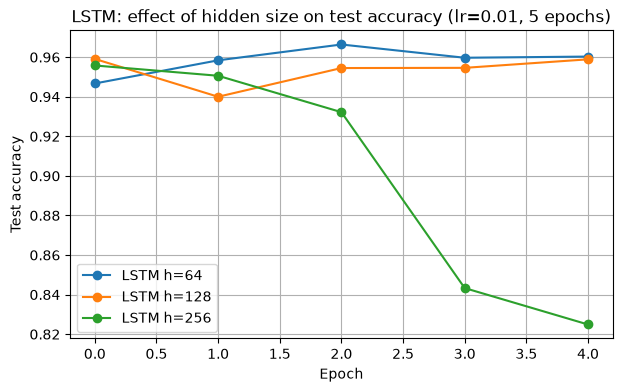

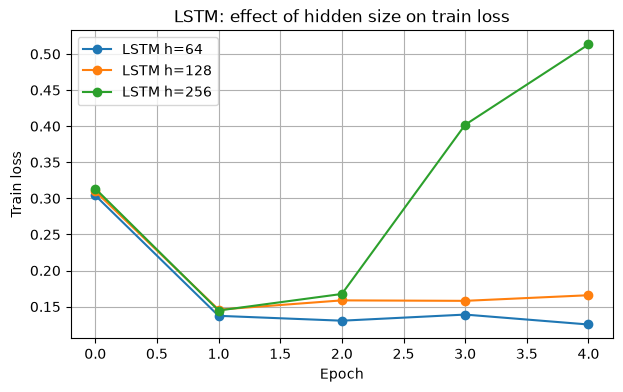

In [10]:
# ===== 3(b) hidden-size sweep for the LSTM =====
lstm_sweep = {}
for h in [64, 128, 256]:
    tag = f'LSTM_h{h}'
    print(f"\n===== Running {tag} =====")
    lstm_sweep[h] = run_mnist_experiment(
        rnn_type='LSTM', hidden_size=h, n_epochs=5, lr=0.01
    )

print("\nLSTM final test accuracy by hidden size:")
for h, hist in lstm_sweep.items():
    print(f"  h={h:>3d}: {hist['test_acc'][-1]:.4f}")

# Plot: test accuracy per epoch for each hidden size
plt.figure(figsize=(7, 4))
for h, hist in lstm_sweep.items():
    plt.plot(hist['test_acc'], marker='o', label=f'LSTM h={h}')
plt.title('LSTM: effect of hidden size on test accuracy (lr=0.01, 5 epochs)')
plt.xlabel('Epoch'); plt.ylabel('Test accuracy')
plt.legend(); plt.grid(True); plt.show()

# Plot: train loss per epoch for each hidden size
plt.figure(figsize=(7, 4))
for h, hist in lstm_sweep.items():
    plt.plot(hist['train_loss'], marker='o', label=f'LSTM h={h}')
plt.title('LSTM: effect of hidden size on train loss')
plt.xlabel('Epoch'); plt.ylabel('Train loss')
plt.legend(); plt.grid(True); plt.show()

In [11]:
writer.close()

### 3(c) Comparison with the CNN from Assignment 1

On MNIST, a correctly trained version of the Assignment 1 CNN reaches ≈99% test
accuracy within a few epochs because convolution exploits 2-D locality, weight
sharing and translation equivariance. The RNN instead treats each image as a
sequence of 28 row vectors, so it does not explicitly model 2-D local
connectivity and must propagate information through 28 recurrent steps. In this
experiment the plain RNN underperforms (**29.77%** at 5 epochs and **37.65%**
at 10 epochs for h = 128; the epoch-to-epoch oscillation suggests optimization
instability rather than a hard limit). Gated RNNs narrow the gap (LSTM
**≈95%**, GRU **≈92%**), but neither matches the CNN.

Parameter counts depend on the CNN baseline: LeNet5 has ≈61.7k parameters,
while an RNN with hidden size 128 has ≈21.5k parameters (21,248 weights plus
266 biases, using PyTorch `nn.RNN` with separate input and recurrent biases).
If instead comparing with the Assignment 1 DCN, that CNN has ≈1.11M parameters,
so the comparison is not capacity-matched. The accuracy gap is therefore mainly
an inductive-bias effect: convolution encodes translation equivariance and
local 2-D structure directly, while a row-wise RNN must learn vertical
relationships through recurrence. Training cost also differs — the RNN is
sequential over time steps and slower per epoch, while the CNN parallelises
over spatial positions.

Similarities: both are trained end-to-end with cross-entropy, both learn
feature representations, and both benefit from normalisation and a well-tuned
learning rate. Differences: the CNN is the better choice for static images; the
RNN/LSTM is preferable when the data is genuinely sequential (e.g. handwriting
strokes, audio or video frames). Gated RNNs recover much of the gap on
row-by-row MNIST because gates mitigate vanishing gradients and help retain
information across the 28 steps.